Radon transform 

- data
  - generate ellipse phantoms
  - run skimage forward Radon
  - add noise, store coefficients
  - So each data point has three components: (Original, Noised Sinogram, Noise coefficients)
- Invert with chosen kernel, evaluate MSE
- (...do numerical analysis)

In [1]:
import numpy as np
import matplotlib.pyplot as plt


import implementation.filter
from implementation.transform import iRadon


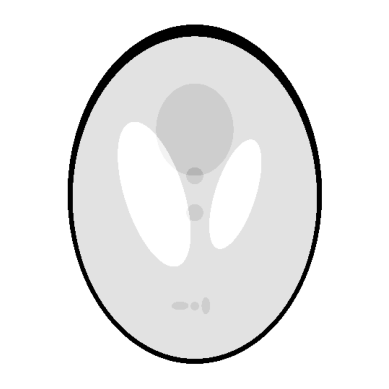

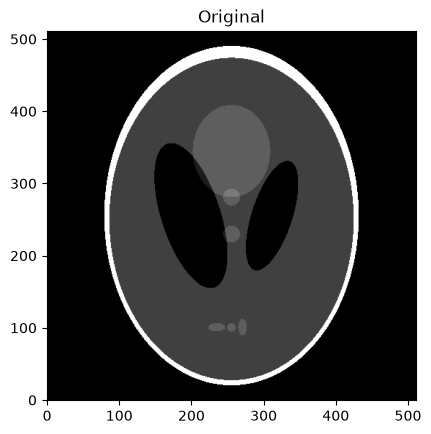

In [2]:
#Generating phantoms

from implementation.phantomgen import phantom

#will do later

image1 = phantom

plt.imshow(image1, cmap=plt.cm.Greys_r, origin='lower')
plt.title("Original")
plt.show()






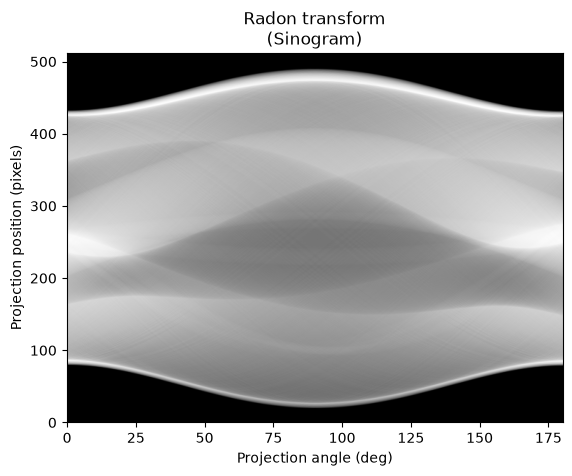

In [3]:
#generate sinogram using skimage radon 

from skimage.transform import radon

theta = np.linspace(0.0, 180.0, max(image1.shape), endpoint=False)
sinogram1 = radon(image1, theta=theta)
dx, dy = 0.5 * 180.0 / max(image1.shape), 0.5 / sinogram1.shape[0]
plt.title("Radon transform\n(Sinogram)")
plt.xlabel("Projection angle (deg)")
plt.ylabel("Projection position (pixels)")
plt.imshow(
    sinogram1,
    cmap=plt.cm.Greys_r,
    extent=(-dx, 180.0 + dx, -dy, sinogram1.shape[0] + dy),
    aspect='auto',
)

plt.show()

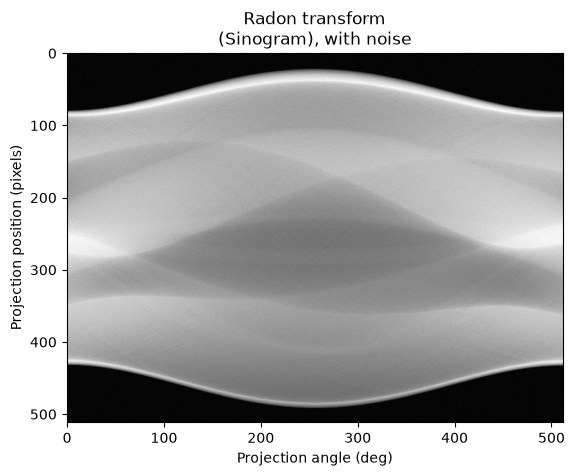

In [4]:
#noising 

from implementation.noise import both_noises

noised_sinogram1 = both_noises(sinogram1, I0=1e4, sigma=0.02, rng_p=0, rng_g=1)

plt.title("Radon transform\n(Sinogram), with noise")
plt.xlabel("Projection angle (deg)")
plt.ylabel("Projection position (pixels)")
plt.imshow(
    noised_sinogram1,
    cmap=plt.cm.Greys_r,
    aspect='auto',
)

plt.show()

FBP with Ramm-lak rms reconstruction error: 0.0484


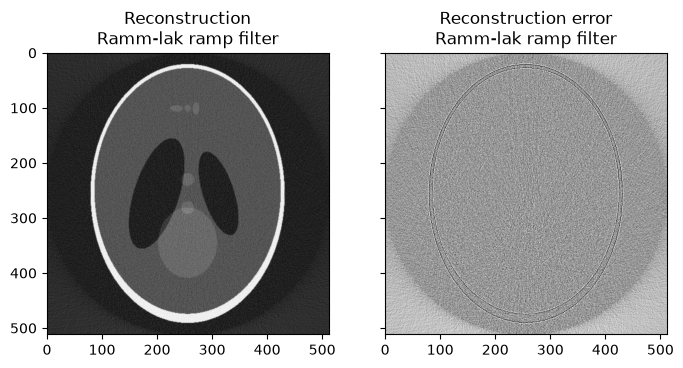

In [9]:
# Reconstruction using filtered back projection

import implementation.filter as filt
from implementation.transform import iRadon


filter1 = filt.RampFilter

# Using our FBP implementation (once we get it working):
#reconstruction1 = iRadon(sinogram=noised_sinogram1, kernel=filter1, resolution=512)

# using Skimage iRadon, with ramm-lak filter, as a placeholder:
from skimage.transform import iradon
#reconstruction1 = iradon(noised_sinogram1, theta=theta, filter_name='ramp')
from implementation.transform import inverseRadon
reconstruction1 = inverseRadon(sinogram=noised_sinogram1, theta_deg=theta, kernel="ramp")


error1 = reconstruction1 - image1

print(f'FBP with Ramm-lak rms reconstruction error: {np.sqrt(np.mean(error1**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nRamm-lak ramp filter")
ax1.imshow(reconstruction1, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nRamm-lak ramp filter")
ax2.imshow(error1, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()


FBP with Hamming rms reconstruction error: 0.0469


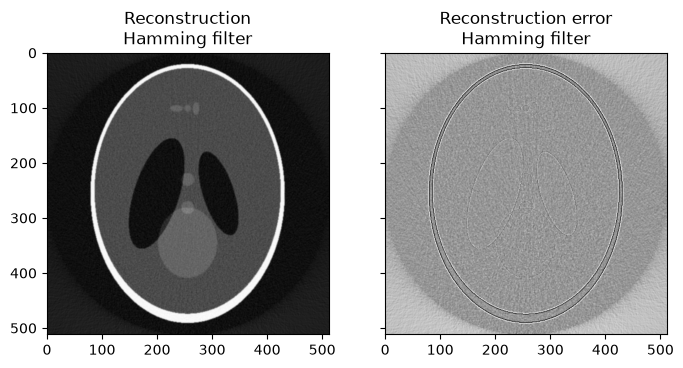

In [10]:
reconstruction1_1 = inverseRadon(sinogram=noised_sinogram1, theta_deg=theta, kernel="hamming")


error1_1 = reconstruction1_1 - image1

print(f'FBP with Hamming rms reconstruction error: {np.sqrt(np.mean(error1_1**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nHamming filter")
ax1.imshow(reconstruction1_1, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nHamming filter")
ax2.imshow(error1_1, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

FBP with Ramm-lak, without noise rms reconstruction error: 0.0348


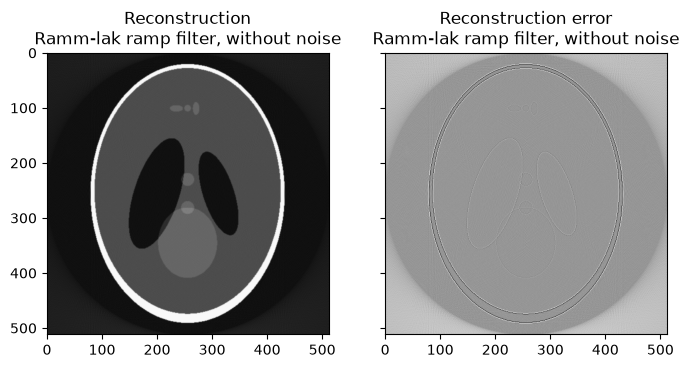

In [11]:
# Without noise, 

from implementation.transform import inverseRadon
reconstruction1_2 = inverseRadon(sinogram=sinogram1, theta_deg=theta, kernel="ramp")


error1_2 = reconstruction1_2 - image1

print(f'FBP with Ramm-lak, without noise rms reconstruction error: {np.sqrt(np.mean(error1_2**2)):.3g}')

imkwargs = dict(vmin=-0.2, vmax=0.2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4.5), sharex=True, sharey=True)
ax1.set_title("Reconstruction\nRamm-lak ramp filter, without noise")
ax1.imshow(reconstruction1_2, cmap=plt.cm.Greys_r)
ax2.set_title("Reconstruction error\nRamm-lak ramp filter, without noise")
ax2.imshow(error1_2, cmap=plt.cm.Greys_r, **imkwargs)
plt.show()

## Conclusion

After passing through with the plain ramm-lak ramp filter, we can see that the noise was amplified.

Using the Hamming filter, the noise in our reconstruction was slightly smoothed, but edge blurring increased. As a result, MSE was only ever-so-slightly decreased, from 0.0484 to 0.0469.

Looking at the inversion of the clean sinogram, it's clear that in all cases we are getting artificial error outside of the circle, so we should just manually mask that out of our reconstruction. 

Strangely, there is increased edge blurring in the Ramm-lak inversion of the noiseless sinogram, compared to the Ramm-lak inversion of the noised sinogram. Not sure if the noise just blurred it out, or if something else is going on.

#### Two different sources of error

As evidenced by the noiseless version, there's error introduced during the reconstruction step which is independent of noise. And then also noise-induced error. 

SINCE FBP IS LINEAR, WE SHOULD(??) be able to split the error into those respective parts, $e_{\text{total}} = e_{\text{FBP}} + e_{\text{noise}}$. 

We could just directly measure each by reconstructing and taking MSE before and after noising the sinogram.

But can we find an approach that uses only the original image and the noisy reconstruction? perhaps taking the MSE over a smaller constant region that doesn't intersect any edges, (and normalize,) and conclude that that is approximately $e_{\text{noise}}$? And then the remainder of the error would be due to edge blurring/projection artifacts?